<a href="https://colab.research.google.com/github/vaniararaandini03/Proyek-ProbStat-TMDB5000/blob/main/Kel4_ProbSta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np

# 1. Membaca dataset TMDB 5000 Movies
# Pastikan nama file sesuai dengan file dataset Anda
df = pd.read_csv("tmdb_5000_movies.csv")

print(f"Jumlah data awal: {len(df)} film")

Jumlah data awal: 4803 film


In [13]:
clean_condition = (
    df['budget'].notnull() & (df['budget'] > 0) &
    df['runtime'].notnull() & (df['runtime'] > 0) &
    df['vote_count'].notnull() & (df['vote_count'] > 0) &
    df['vote_average'].notnull() & (df['vote_average'] > 0)
)

df_clean = df[clean_condition].copy()

print(f"Jumlah data setelah pembersihan: {len(df_clean)} film")
print(f"Persentase data dipertahankan: {len(df_clean) / len(df) * 100:.2f}%\n")

Jumlah data setelah pembersihan: 3752 film
Persentase data dipertahankan: 78.12%



In [14]:
def hitung_statistik_deskriptif(df_input, kolom_nama):
    data = df_input[kolom_nama].dropna()

    n = len(data)
    mean_val = data.mean()
    median_val = data.median()
    std_val = data.std() # Simpangan baku sampel (ddof=1)
    min_val = data.min()
    q1_val = data.quantile(0.25)
    q3_val = data.quantile(0.75)
    max_val = data.max()
    iqr_val = q3_val - q1_val

    hasil = {
        "Ukuran Statistik": [
            "Jumlah data", "Rata-rata", "Median", "Simpangan baku",
            "Minimum", "Kuartil Pertama (Q1)", "Kuartil Ketiga (Q3)",
            "Maksimum", "IQR"
        ],
        kolom_nama: [
            n, mean_val, median_val, std_val,
            min_val, q1_val, q3_val, max_val, iqr_val
        ]
    }
    return pd.DataFrame(hasil)

In [15]:
variabel_list = ['vote_average', 'popularity', 'runtime', 'budget']

for var in variabel_list:
    df_stat = hitung_statistik_deskriptif(df_clean, var)
    print(f"=== Tabel Statistik Deskriptif: {var} ===")
    print(df_stat.to_string(index=False))
    print("\n" + "="*45 + "\n")

=== Tabel Statistik Deskriptif: vote_average ===
    Ukuran Statistik  vote_average
         Jumlah data   3752.000000
           Rata-rata      6.245442
              Median      6.300000
      Simpangan baku      0.905792
             Minimum      2.000000
Kuartil Pertama (Q1)      5.700000
 Kuartil Ketiga (Q3)      6.900000
            Maksimum     10.000000
                 IQR      1.200000


=== Tabel Statistik Deskriptif: popularity ===
    Ukuran Statistik  popularity
         Jumlah data 3752.000000
           Rata-rata   26.079686
              Median   17.661192
      Simpangan baku   34.467189
             Minimum    0.001586
Kuartil Pertama (Q1)    8.085403
 Kuartil Ketiga (Q3)   34.009847
            Maksimum  875.581305
                 IQR   25.924444


=== Tabel Statistik Deskriptif: runtime ===
    Ukuran Statistik     runtime
         Jumlah data 3752.000000
           Rata-rata  109.411247
              Median  106.000000
      Simpangan baku   20.615822
           

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
file_path = '3TIE_04_tmdb5000movies.xlsx'
df = pd.read_excel(file_path, sheet_name='Data Bersih')

# Menampilkan data
print(df.head())
print("Jumlah data:", df.shape)

       id                                     title release_date  popularity  \
0   19995                                    Avatar   2009-12-10  150.437577   
1     285  Pirates of the Caribbean: At World's End   2007-05-19  139.082615   
2  206647                                   Spectre   2015-10-26  107.376788   
3   49026                     The Dark Knight Rises   2012-07-16  112.312950   
4   49529                               John Carter   2012-03-07   43.926995   

   vote_average  vote_count     budget  runtime  
0           7.2       11800  237000000      162  
1           6.9        4500  300000000      169  
2           6.3        4466  245000000      148  
3           7.6        9106  250000000      165  
4           6.1        2124  260000000      132  
Jumlah data: (3752, 8)


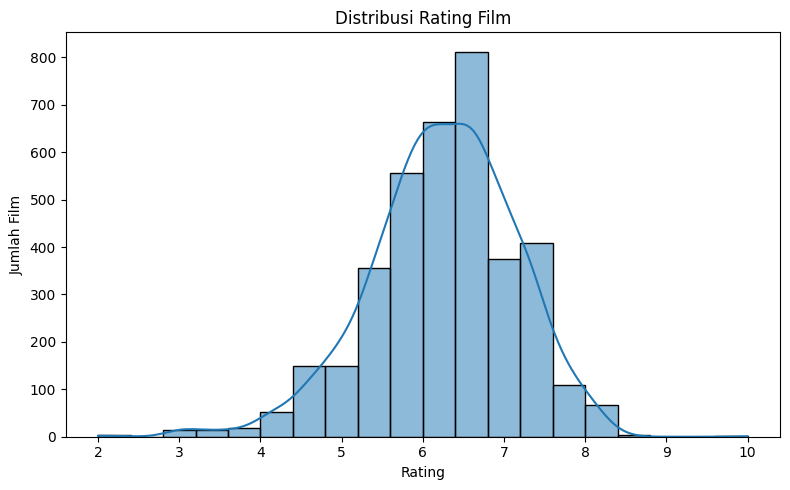

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['vote_average'], bins=20, kde=True)

plt.title('Distribusi Rating Film')
plt.xlabel('Rating')
plt.ylabel('Jumlah Film')
plt.tight_layout()
plt.show()

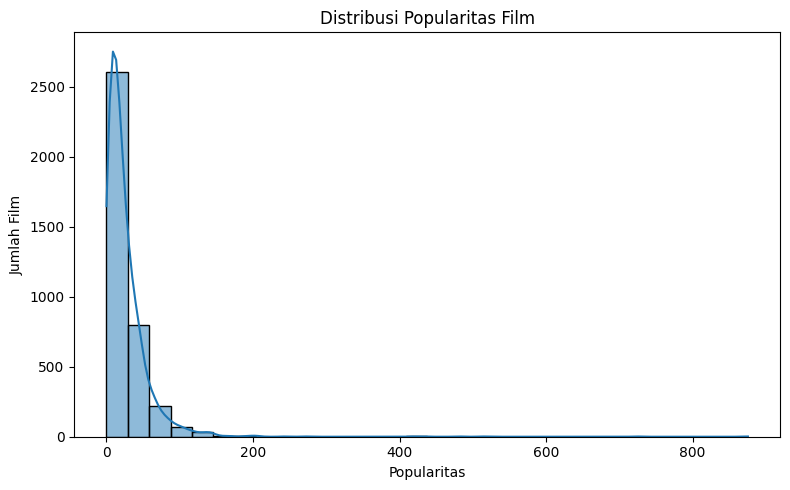

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['popularity'], bins=30, kde=True)

plt.title('Distribusi Popularitas Film')
plt.xlabel('Popularitas')
plt.ylabel('Jumlah Film')
plt.tight_layout()
plt.show()

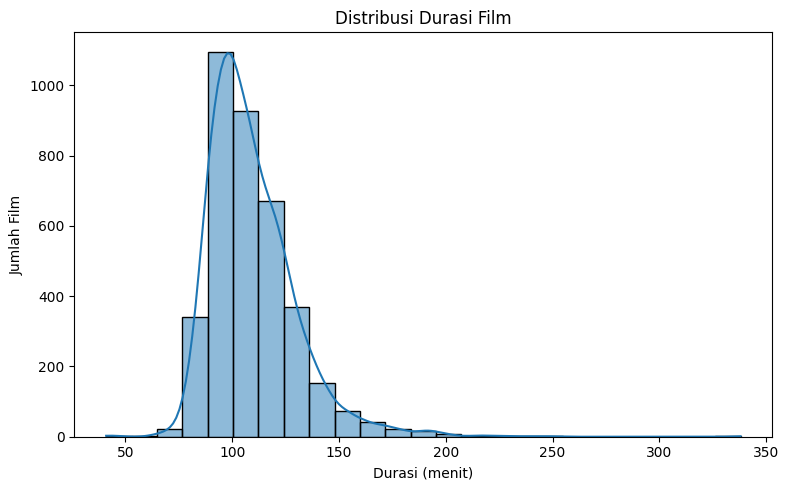

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['runtime'].dropna(), bins=25, kde=True)

plt.title('Distribusi Durasi Film')
plt.xlabel('Durasi (menit)')
plt.ylabel('Jumlah Film')
plt.tight_layout()
plt.show()

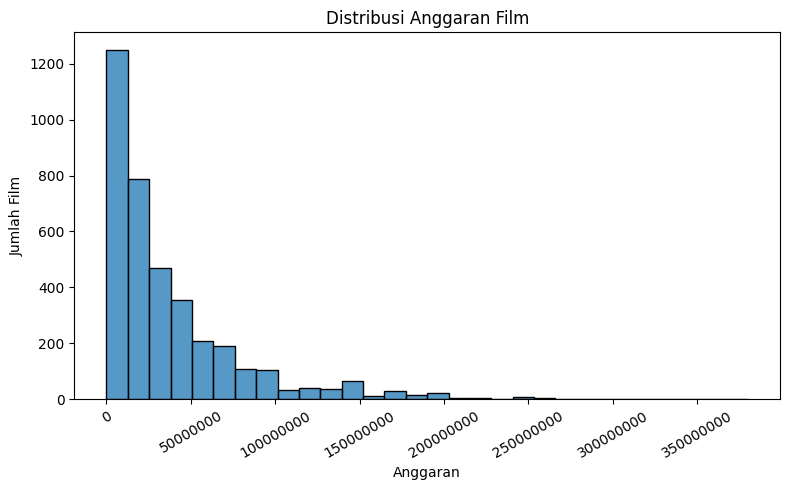

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['budget'].dropna(), bins=30)

plt.title('Distribusi Anggaran Film')
plt.xlabel('Anggaran')
plt.ylabel('Jumlah Film')
plt.ticklabel_format(style='plain', axis='x')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

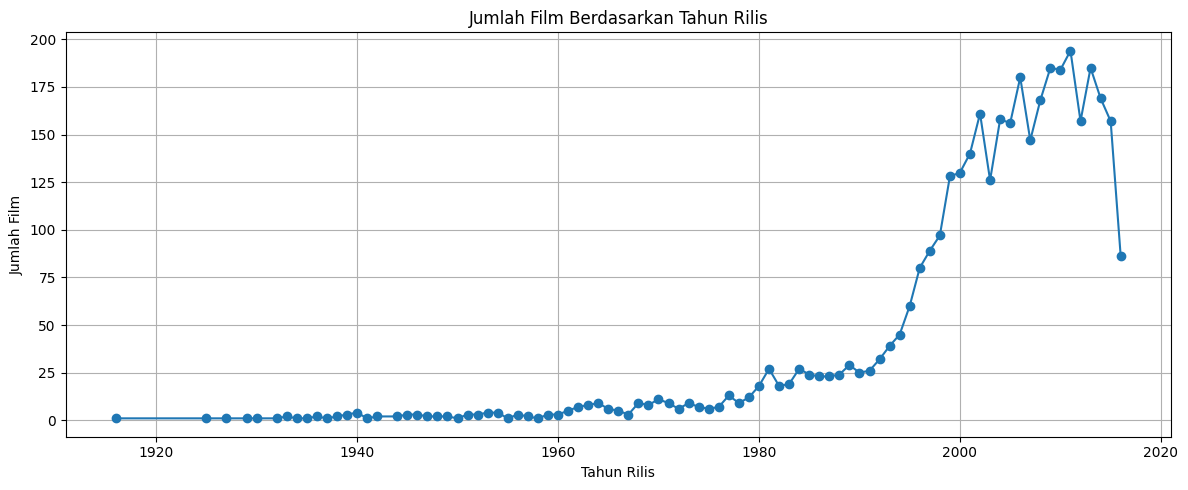

In [ ]:
df['release_date'] = pd.to_datetime(
    df['release_date'], errors='coerce'
)

df['tahun'] = df['release_date'].dt.year

jumlah_film = df['tahun'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
jumlah_film.plot(kind='line', marker='o')

plt.title('Jumlah Film Berdasarkan Tahun Rilis')
plt.xlabel('Tahun Rilis')
plt.ylabel('Jumlah Film')
plt.grid(True)
plt.tight_layout()
plt.show()

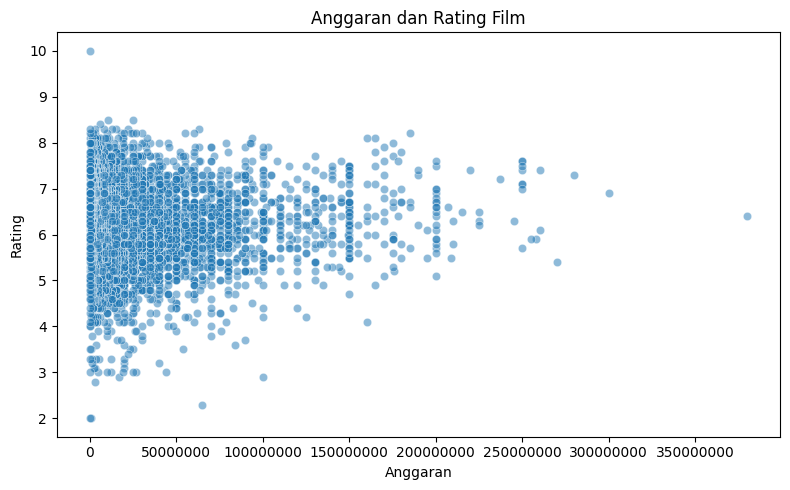

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='budget',
    y='vote_average',
    alpha=0.5
)

plt.title('Anggaran dan Rating Film')
plt.xlabel('Anggaran')
plt.ylabel('Rating')
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

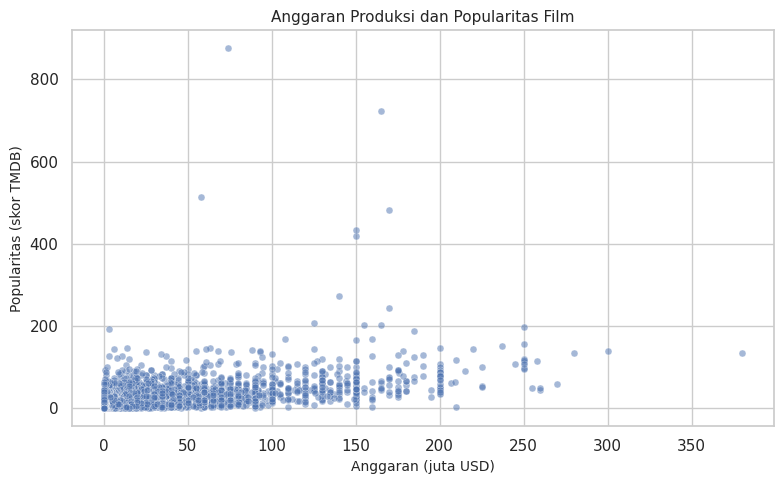

In [ ]:
if df['budget'].max() > 1000:
    df['budget_juta'] = df['budget'] / 1_000_000
else:
    df['budget_juta'] = df['budget']

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='budget_juta',
    y='popularity',
    alpha=0.5,       # Membuat titik transparan seperti di gambar
    s=25            # Ukuran titik
)

plt.title('Anggaran Produksi dan Popularitas Film', fontsize=11)
plt.xlabel('Anggaran (juta USD)', fontsize=10)
plt.ylabel('Popularitas (skor TMDB)', fontsize=10)

plt.tight_layout()
plt.show()

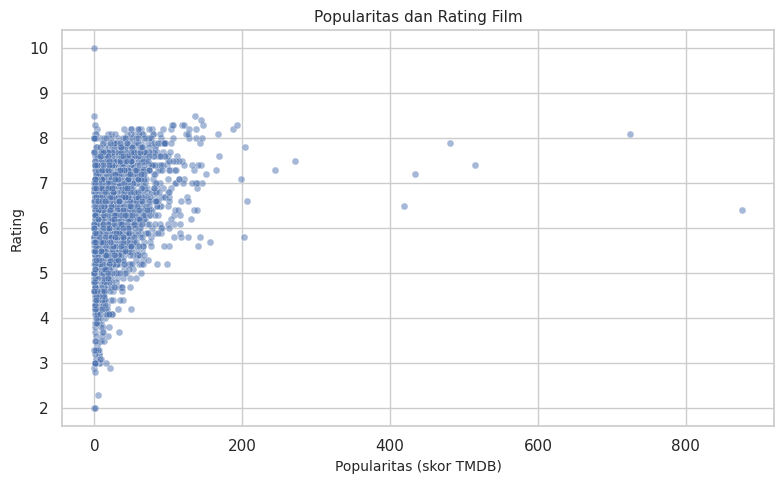

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='popularity',
    y='vote_average',
    alpha=0.5,       # Transparansi titik
    s=25            # Ukuran titik
)

plt.title('Popularitas dan Rating Film', fontsize=11)
plt.xlabel('Popularitas (skor TMDB)', fontsize=10)
plt.ylabel('Rating', fontsize=10)

plt.tight_layout()
plt.show()